### Exercício 1

In [40]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import freqz, lfilter
from scipy.io import wavfile
import sounddevice as sd
import time
from math import *
import random
from os import path 
from scipy import signal

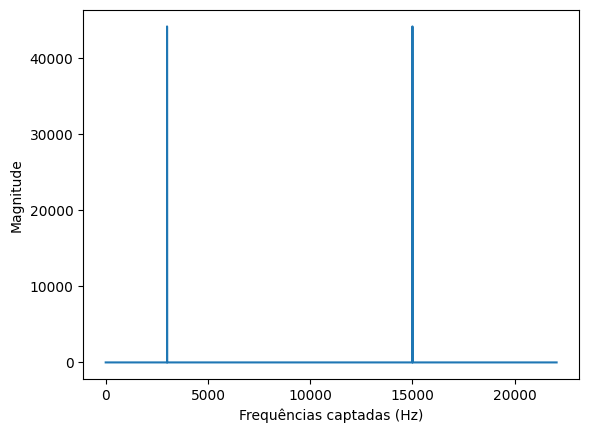

In [41]:
def calculo_FFT(dados, freqAmostra): 
    qtd_amostras = len(dados)
    yf = np.abs(np.fft.rfft(dados))
    xf = np.fft.rfftfreq(qtd_amostras, d=1/freqAmostra)
    return xf,yf 


freqDeAmostragem = 44100

tempo = np.linspace(0, 2, freqDeAmostragem*2, endpoint=False)
portadora = np.sin(2*pi*15000*tempo) 
dados = np.sin(2*pi*3000*tempo)

sinal_resultante = portadora + dados

xf, yf = calculo_FFT(sinal_resultante, freqDeAmostragem)

plt.plot(xf, yf)
plt.xlabel("Frequências captadas (Hz)")
plt.ylabel("Magnitude")
plt.show()




### Exercício 2

A banda mínima seria 13000 Hz, pois na multiplicação desses senos, a resposta gerada fica em [Fp - Fa, Fp + Fa]

### Exercício 3

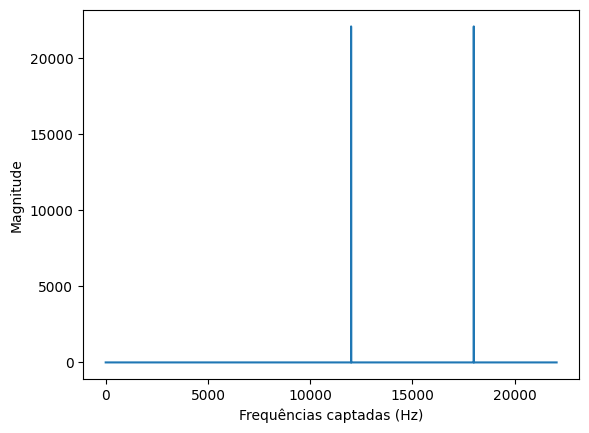

In [42]:
sinal_resultante = portadora*dados 

xf, yf = calculo_FFT(sinal_resultante, freqDeAmostragem)

plt.plot(xf, yf)
plt.xlabel("Frequências captadas (Hz)")
plt.ylabel("Magnitude")
plt.show()


### Exercício 4

Precisaríamos passar o sinal por um filtro passa-baixa para ele apenas pegar sinais abaixo de 1000 Hz. Isso deve acontecer pois após a transformação com a portadora, o sinal deve ir de Fp - Fa até Fp + Fa. Como a portadora é 15kHz e a amplitude é de 14kHz até 16kHz, a frequência de amostra deve ser no máximo 1000 Hz

### Exercício 5

Tocando o áudio
Tocando o áudio modulado
Tocando o áudio desmodulado


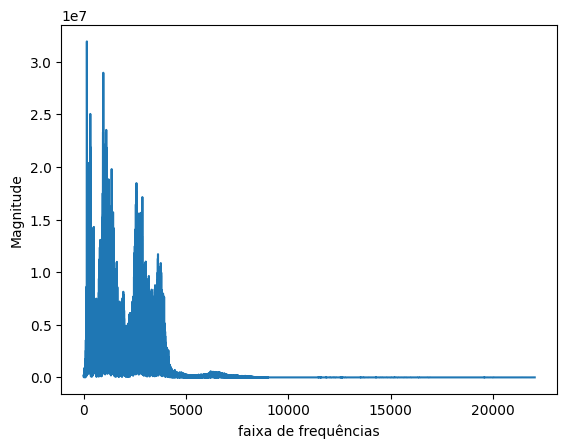

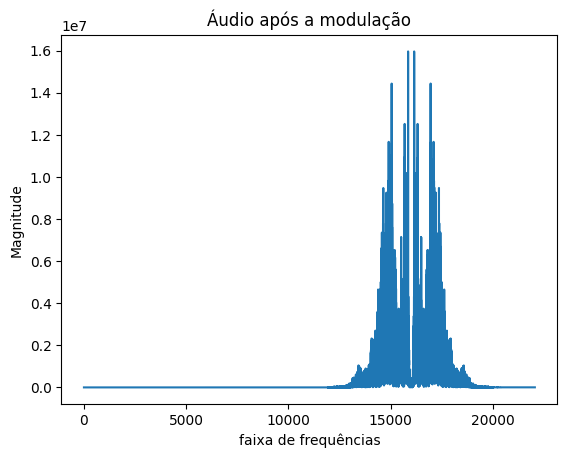

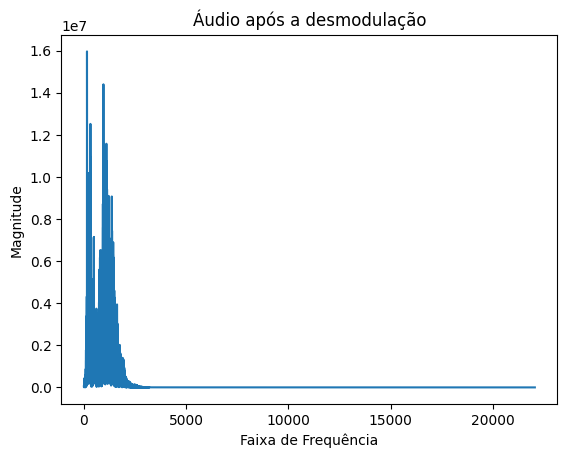

In [44]:
def passa_baixa (sinal, fc, fs, ordem=4): 
    nyq = fs / 2
    b, a = signal.butter(ordem, fc/nyq, btype="low")
    return signal.filtfilt(b, a, sinal)


f_amostra, audio = wavfile.read("gravacao.wav")
tempo = np.linspace(0, 5, f_amostra*5, endpoint=False)

sd.play(audio, f_amostra)
print("Tocando o áudio")
sd.wait()

xf, yf = calculo_FFT(audio[:f_amostra*5], f_amostra)

dados = passa_baixa(audio[:f_amostra*5], 2000, f_amostra)
portadora = np.sin(2*pi*16000*tempo)
sinal_modulado = portadora*dados 
sd.play(sinal_modulado, f_amostra)
print("Tocando o áudio modulado")
sd.wait()

xf_mod, yf_mod = calculo_FFT(sinal_modulado, f_amostra)

sinal_desmodulado = sinal_modulado*portadora

filtrado = passa_baixa(sinal_desmodulado, 2000, f_amostra)

xf_desmod, yf_desmod = calculo_FFT(filtrado, f_amostra)

sd.play(filtrado, f_amostra)
print("Tocando o áudio desmodulado")
sd.wait()

plt.figure()
plt.plot(xf, yf)
plt.xlabel("faixa de frequências")
plt.ylabel("Magnitude")
plt.show()

plt.plot(xf_mod, yf_mod)
plt.title("Áudio após a modulação")
plt.xlabel("faixa de frequências")
plt.ylabel("Magnitude")
plt.show()

plt.plot(xf_desmod, yf_desmod)
plt.title("Áudio após a desmodulação")
plt.xlabel("Faixa de Frequência")
plt.ylabel("Magnitude")
plt.show()